In [2]:
import torch
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim

In [3]:
class RuscoDataset():

    def __init__(self, data_file):

        all_data = pd.read_csv( data_file, dtype={'day':np.int32,
                                                    'month':np.int32,
                                                    'year':np.int32,
                                                    't2m_now':np.float64,
                                                    't2m_next':np.float64 } )

        self.input_data = (all_data[ ["day", "month", "year", "t2m_now"] ]).copy()
        self.pred_temps = (all_data[ ["t2m_next"] ]).copy()
    
    def __len__(self):
        return len(self.pred_temps)
    
    def __getitem__(self, indx):

        giorno = self.input_data["day"].iloc[indx].item()
        mese = self.input_data["month"].iloc[indx].item()
        anno = self.input_data["year"].iloc[indx].item()
        now_temp = self.input_data["t2m_now"].iloc[indx].item()
        next_temp = self.pred_temps["t2m_next"].iloc[indx].item()

        dati_input = (giorno, mese, anno, now_temp)

        return torch.as_tensor(dati_input, dtype=torch.float32), torch.as_tensor(next_temp, dtype=torch.float32)



In [4]:
train_dataset = RuscoDataset("/home/federico_menegazzo/Desktop/Programming/python_projects/analisi_dati_ki/poggio_rusco/train_rusco_data.csv")
test_dataset = RuscoDataset("/home/federico_menegazzo/Desktop/Programming/python_projects/analisi_dati_ki/poggio_rusco/test_rusco_data.csv")

print(len(train_dataset))
print(len(test_dataset))


train_dataloader = DataLoader(train_dataset, batch_size=21, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)

2919
1094


In [5]:
class StdNet(nn.Module):

    def __init__(self):

        super().__init__()
        self.lay1 = nn.Linear(4, 512)
        self.lay2 = nn.Linear(512, 512)
        self.lay3 = nn.Linear(512, 512)
        self.lay4 = nn.Linear(512, 1)

    def forward(self, x):

        x = torch.sigmoid(self.lay1(x))
        x = torch.sigmoid(self.lay2(x))
        x = torch.sigmoid(self.lay3(x))
        x = self.lay4(x)

        return x[:, 0]



ReteKi = StdNet()
parametri_rete = torch.load("./parametri_rete_ki/parametri_rete_ki.pth",weights_only=True)

ReteKi.load_state_dict(parametri_rete)

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

ReteKi = ReteKi.to(device)


cuda:0


In [10]:

input_data, out_temp = next( iter(test_dataloader) )

print(f"dati input: {input_data}")
print(f"temperatura effettiva {out_temp}")
print(f"temperatura calcolata { ReteKi(input_data.to(device)) }")

dati input: tensor([[30.0000,  5.0000, 24.0000, 15.2217]])
temperatura effettiva tensor([14.1460])
temperatura calcolata tensor([13.4799], device='cuda:0', grad_fn=<SelectBackward0>)


In [11]:
criterion = nn.MSELoss(reduction='mean')
optimizer = optim.Adam(ReteKi.parameters(),lr=0.001)

for epoch in range(10):

    epoch_loss = 0

    for j, data in enumerate(train_dataloader, 0):

        input_data, out_temp = data[0].to(device), data[1].to(device)

        optimizer.zero_grad()

        net_output = ReteKi(input_data)
        loss = criterion(net_output, out_temp)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * (1/139)


    print(f"epoch: {epoch}, loss: {epoch_loss}")

epoch: 0, loss: 0.12401743499702844
epoch: 1, loss: 0.10376552273619843
epoch: 2, loss: 0.10373503444783341
epoch: 3, loss: 0.11664862213019783
epoch: 4, loss: 0.14278020786134885
epoch: 5, loss: 0.15123854542700504
epoch: 6, loss: 0.12068738171616372
epoch: 7, loss: 0.10793648527268476
epoch: 8, loss: 0.10402386898690792
epoch: 9, loss: 0.10784327872968524


In [13]:
def test_net(net, test_loader):

    avg_error = 0

    for j, data in enumerate(test_loader, 0):

        input_data, out_temp = data[0].to(device), data[1].to(device)
        
        net_output = net(input_data)
        avg_error += ((net_output - out_temp)**2) * (1/len(test_loader))

    return avg_error



print(f"test results: {test_net(ReteKi, test_dataloader)}")

    

test results: tensor([9.3939], device='cuda:0', grad_fn=<AddBackward0>)


In [14]:

torch.save(ReteKi.state_dict(), f'./parametri_rete_ki/parametri_rete_ki.pth')

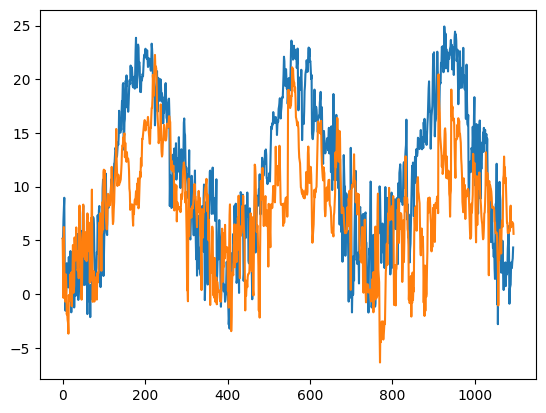

In [19]:

raw_test_data = pd.read_csv( "/home/federico_menegazzo/Desktop/Programming/python_projects/analisi_dati_ki/poggio_rusco/test_rusco_data.csv", dtype = {'day':np.int32,
                                                                           'month':np.int32,
                                                                           'year':np.int32,
                                                                           't2m_now':np.float32,
                                                                           't2m_next':np.float32} )

iterative_model = [5.15]

x_0 = 5.159420000000011

for indx, entry in raw_test_data.iterrows():

    giorno = entry["day"]
    mese = entry["month"]
    anno = entry["year"]

    input_entry = np.array([giorno, mese, anno, x_0])

    tensor_input_entry = torch.as_tensor( input_entry, dtype=torch.float32).unsqueeze(0)

    pred_temp = ReteKi(tensor_input_entry.to(device))
    iterative_model.append(pred_temp[0].cpu().detach().numpy())

    x_0 = pred_temp[0].cpu().detach().numpy()



plt.plot(raw_test_data["t2m_now"].values)
plt.plot(iterative_model)
plt.show()